# 08 — Experimentos QAOA sobre o QUBO do problema de alocação
Executa **E05 (QAOA padrão), E06 (warm-start), E07 (CVaR-QAOA), E09 (ruído) e E10 (fora da amostra, parcial)** sobre os QUBOs do experimento 07 (8 qubits), e compara com **busca exaustiva, simulated annealing e busca aleatória**.

**Separação obrigatória:** *desempenho computacional* (probabilidade de achar o mínimo do QUBO, razão de aproximação, nº de avaliações, profundidade/CX) **×** *qualidade hidrológica* (J exato e déficits do plano escolhido). Um QAOA que acha o mínimo do QUBO **não** acha, por isso, o plano hidrologicamente ótimo: o QUBO é um substituto aproximado.

Simulação **ideal** (vetor de estado exato, sem ruído de amostragem) salvo onde indicado. Nada aqui é evidência de vantagem quântica: o espaço tem só 256 estados.

In [1]:
import sys, json, time; sys.path.insert(0, '..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.data.loaders import load_portal_volume
from src.hydrology.evaporation import load_power, penman_open_water_mm
from src.scenarios.generator import ScenarioGenerator
from src.scenarios import synthetic as S, temporal as T
from src.optimization.problem import make_instance
from src.optimization.classical.milp import solve_milp
from src.optimization.classical.baselines import plan_linear, plan_priority
from src.optimization.classical.heuristics import simulated_annealing, random_search
from src.optimization import discrete as Dd
from src.optimization.qubo.surrogate import fit_qubo, basis_index
from src.optimization.quantum import qaoa as Q
from src.evaluation.metrics import summarize

vol = load_portal_volume('../data/reserv-ors-capac-175236-portal-hidrologico-ce.csv')
met = load_power('../data/raw/meteo/nasa_power_oros_daily.json'); met['E_mm_day'] = penman_open_water_mm(met)
gen = ScenarioGenerator(vol, met)
CFGS = {'B': S.CONFIG_B, 'C': S.CONFIG_C}; LAM, ALPHA = 0.5, 0.8; SEEDS = list(range(10))
SEQ = {k: gen.inflow_sequences(c) for k, c in CFGS.items()}
INST = {k: make_instance(SEQ[k], c, 200, f'{k}_200_2', demand_scale=2) for k, c in CFGS.items()}
dz = Dd.Discretization(2); X = dz.all_bitstrings()
CASE = {}
for ck, inst in INST.items():
    df = Dd.enumerate_all(inst, dz, LAM, ALPHA); J = df.J.values
    for tag, tau in (('principal', None), ('diag_tau20', 20.0)):
        Qm, d = fit_qubo(X, J, tau); prob = Q.make_problem(Qm)
        CASE[(ck, tag)] = dict(Q=Qm, prob=prob, J=J, J_le=Dd.to_little_endian(J, X), diag=d, df=df, inst=inst,
                               i_true=int(np.argmin(Dd.to_little_endian(J, X))), i_qgs=int(np.argmin(prob.raw_energies)))
    cont = solve_milp(inst, LAM, ALPHA); CASE[(ck, 'cont')] = cont
for k in CASE:
    if k[1] != 'cont': print(k, 'mínimo QUBO == ótimo real?', CASE[k]['i_qgs'] == CASE[k]['i_true'], '| gap J do mín. QUBO:', round(CASE[k]['diag']['gap_true_J'], 2))

('B', 'principal') mínimo QUBO == ótimo real? False | gap J do mín. QUBO: 5.44
('B', 'diag_tau20') mínimo QUBO == ótimo real? True | gap J do mín. QUBO: 0.0
('C', 'principal') mínimo QUBO == ótimo real? False | gap J do mín. QUBO: 4.22
('C', 'diag_tau20') mínimo QUBO == ótimo real? True | gap J do mín. QUBO: 0.0


In [2]:
def metrics(c, pv):
    prob, Jl = c['prob'], c['J_le']; raw = prob.raw_energies
    top = np.argsort(Jl)[:13]  # melhores ~5 % pelo J exato
    return dict(AR=(raw.mean() - pv @ raw) / (raw.mean() - raw.min()), P_qubo_gs=pv[c['i_qgs']], P_true_opt=pv[c['i_true']],
                P_top5pct_true=pv[top].sum(), J_exp=pv @ Jl, J_gap_exp=pv @ Jl - Jl.min(),
                lift_vs_uniform=pv[c['i_qgs']] * len(pv), shots_to_99=float(np.log(0.01) / np.log(1 - min(pv[c['i_qgs']], 1 - 1e-12))))

def best_of_shots(c, pv, seed, shots=1024):
    # escolhe a melhor amostra pela energia do QUBO (a única que o algoritmo quântico conhece)
    s = np.random.default_rng(1000 + seed).choice(len(pv), size=shots, p=pv / pv.sum())
    i = s[np.argmin(c['prob'].raw_energies[s])]
    return i, c['J_le'][i] - c['J_le'].min()

# ponto de partida do warm-start: plano do MILP CONTÍNUO arredondado aos níveis (informação clássica explícita)
def warm_bits(ck): return dz.relax_to_bits(Dd.block_fractions(CASE[(ck, 'cont')]['a'], INST[ck]))
for ck in CFGS: print(ck, 'warm-start bits (do MILP contínuo arredondado):', ''.join(map(str, warm_bits(ck))), '| ótimo real:', CASE[(ck, 'principal')]['df'].bits[np.argmin(CASE[(ck, 'principal')]['J'])])

B warm-start bits (do MILP contínuo arredondado): 11111010 | ótimo real: 11110001
C warm-start bits (do MILP contínuo arredondado): 11111111 | ótimo real: 11110111


## E05 / E06 / E07 — QAOA padrão, warm-start e CVaR-QAOA (10 sementes, p = 1, 2, 3)
**Aviso sobre métricas.** Com 1024 amostras num espaço de apenas 256 estados, a *melhor amostra pela energia do QUBO* acha o mínimo do QUBO quase sempre **mesmo com amostragem uniforme** (falha ≈ (255/256)^1024 ≈ 2 %). Por isso `shot_found_*` é **pouco informativo** e NÃO é usado para comparar algoritmos. Métricas usadas: probabilidade por amostra do mínimo do QUBO (`P_qubo_gs`; **uniforme = 1/256 ≈ 0,0039**), `lift_vs_uniform = P·256`, `shots_to_99` (amostras para 99 % de confiança de ver o mínimo) e razão de aproximação (AR; uniforme = 0).

In [3]:
rows, store = [], {}
t0 = time.time()
for tag in ('principal', 'diag_tau20'):
    for ck in CFGS:
        c = CASE[(ck, tag)]; wt = Q.warm_theta_from_bits(np.array(list(map(int, dz.relax_to_bits(Dd.block_fractions(CASE[(ck, 'cont')]['a'], INST[ck]))))), eps=0.25)
        variants = [('standard', {}), ('warm', dict(warm_theta=wt)), ('cvar_a0.25', dict(cvar_alpha=0.25)), ('cvar_a0.10', dict(cvar_alpha=0.10))] if tag == 'principal' else [('standard', {}), ('warm', dict(warm_theta=wt))]
        for vname, kw in variants:
            for p in ((1, 2, 3) if tag == 'principal' else (2, 3)):
                for sd in SEEDS:
                    r = Q.run_qaoa(c['prob'], p, sd, variant=('cvar' if vname.startswith('cvar') else vname), **kw)
                    m = metrics(c, r['probs']); i, gap = best_of_shots(c, r['probs'], sd)
                    rows.append(dict(qubo=tag, cfg=ck, variant=vname, p=p, seed=sd, nfev=r['nfev'], shot_best_true_gap=gap, shot_found_true_opt=bool(i == c['i_true']),
                                     shot_found_qubo_gs=bool(i == c['i_qgs']), **m))
                    store[(tag, ck, vname, p, sd)] = r
print('tempo (s):', round(time.time() - t0))
R = pd.DataFrame(rows); R.to_csv('../results/exp08_qaoa_runs.csv', index=False)
agg = R[R.qubo == 'principal'].groupby(['cfg', 'variant', 'p']).agg(AR=('AR', 'mean'), P_qubo_gs=('P_qubo_gs', 'mean'), P_true_opt=('P_true_opt', 'mean'), P_top5=('P_top5pct_true', 'mean'),
        lift_vs_uniform=('lift_vs_uniform', 'mean'), shots_to_99=('shots_to_99', 'median'), J_gap_exp=('J_gap_exp', 'mean'), shot_gap=('shot_best_true_gap', 'mean'), nfev=('nfev', 'mean')).round(3)
agg

tempo (s): 135


AR  P_qubo_gs  P_true_opt  P_top5  lift_vs_uniform  \
cfg variant    p                                                          
B   cvar_a0.10 1  0.559      0.042       0.018   0.240           10.761   
               2  0.621      0.068       0.027   0.330           17.328   
               3  0.687      0.094       0.048   0.437           24.020   
    cvar_a0.25 1  0.566      0.041       0.018   0.242           10.460   
               2  0.629      0.074       0.033   0.354           18.892   
               3  0.718      0.125       0.065   0.511           32.058   
    standard   1  0.575      0.040       0.018   0.241           10.186   
               2  0.695      0.087       0.037   0.401           22.210   
               3  0.716      0.093       0.043   0.446           23.701   
    warm       1  0.755      0.048       0.009   0.670           12.160   
               2  0.818      0.073       0.011   0.798           18.748   
               3  0.824      0.077       0.011   0.809           19.722   
C   cvar_a0.10 1  0.813      0.061       0.089   0.608           15.646   
               2  0.787      0.081       0.083   0.572           20.839   
               3  0.811      0.095       0.090   0.617           24.446   
    cvar_a0.25 1  0.848      0.056       0.104   0.690           14.424   
               2  0.853      0.084       0.118   0.716           21.459   
               3  0.859      0.087       0.126   0.732           22.295   
    standard   1  0.876      0.030       0.109   0.767            7.805   
               2  0.914      0.022       0.116   0.841            5.671   
               3  0.933      0.015       0.085   0.892            3.786   
    warm       1  0.921      0.071       0.107   0.875           18.138   
               2  0.941      0.074       0.119   0.927           18.849   
               3  0.939      0.060       0.111   0.918           15.436   

                  shots_to_99  J_gap_exp  shot_gap   nfev  
cfg variant    p                                           
B   cvar_a0.10 1      107.237     29.897     5.441   92.6  
               2       74.436     26.720     5.441  280.4  
               3       43.568     22.075     5.441  182.5  
    cvar_a0.25 1      110.385     29.072     5.441   80.9  
               2       77.066     25.827     5.441  297.9  
               3       31.596     20.229     5.441  300.0  
    standard   1      113.427     28.312     5.441   54.7  
               2       56.539     21.955     5.441  263.9  
               3       41.978     20.778     5.441  300.0  
    warm       1       94.626     17.473     5.441   50.0  
               2       58.293     14.444     5.441  286.0  
               3       61.492     14.047     5.441  300.0  
C   cvar_a0.10 1       73.024     13.527     4.216   88.8  
               2       54.345     15.659     4.216  299.5  
               3       46.952     14.280     4.216  275.7  
    cvar_a0.25 1       79.408     10.792     4.216   71.5  
               2       60.211     10.833     4.216  300.0  
               3       55.101     10.535     4.216  283.4  
    standard   1      148.733      8.295     4.216   51.3  
               2      262.023      5.484     4.216  299.2  
               3      293.326      3.721     4.216  300.0  
    warm       1       62.669      5.389     4.216   57.2  
               2       52.754      3.981     4.216  300.0  
               3       77.856      3.970     4.216  300.0

In [4]:
agg2 = R[R.qubo == 'diag_tau20'].groupby(['cfg', 'variant', 'p']).agg(AR=('AR', 'mean'), P_qubo_gs=('P_qubo_gs', 'mean'), P_true_opt=('P_true_opt', 'mean'), J_gap_exp=('J_gap_exp', 'mean'), shot_true_opt_rate=('shot_found_true_opt', 'mean')).round(3)
print('QUBO diagnóstico (τ=20; seu mínimo = ótimo real):'); agg2

QUBO diagnóstico (τ=20; seu mínimo = ótimo real):


AR  P_qubo_gs  P_true_opt  J_gap_exp  shot_true_opt_rate
cfg variant  p                                                             
B   standard 2  0.696      0.048       0.048     21.693                 1.0
             3  0.718      0.062       0.062     20.372                 1.0
    warm     2  0.834      0.015       0.015     13.501                 1.0
             3  0.847      0.018       0.018     12.588                 1.0
C   standard 2  0.913      0.115       0.115      5.669                 1.0
             3  0.936      0.086       0.086      3.790                 1.0
    warm     2  0.942      0.123       0.123      3.847                 1.0
             3  0.939      0.109       0.109      3.844                 1.0

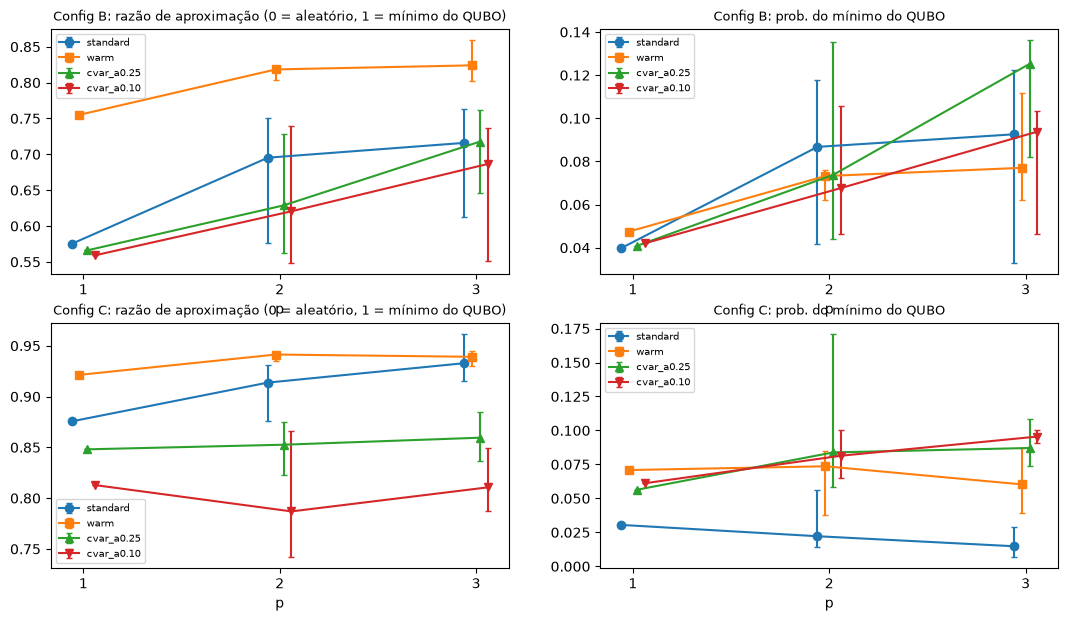

In [5]:
fig, axs = plt.subplots(2, 2, figsize=(13, 7))
for r_, ck in enumerate(CFGS):
    d = R[(R.qubo == 'principal') & (R.cfg == ck)]
    for ax, col, ttl in ((axs[r_, 0], 'AR', 'razão de aproximação (0 = aleatório, 1 = mínimo do QUBO)'), (axs[r_, 1], 'P_qubo_gs', 'prob. do mínimo do QUBO')):
        for v, mk in (('standard', 'o'), ('warm', 's'), ('cvar_a0.25', '^'), ('cvar_a0.10', 'v')):
            m_ = d[d.variant == v].groupby('p')[col].agg(['mean', 'min', 'max'])
            ax.errorbar(m_.index + {'standard': -.06, 'warm': -.02, 'cvar_a0.25': .02, 'cvar_a0.10': .06}[v], m_['mean'], yerr=[m_['mean'] - m_['min'], m_['max'] - m_['mean']], fmt=mk + '-', capsize=2, label=v)
        ax.set_title(f'Config {ck}: {ttl}', fontsize=9); ax.set_xticks([1, 2, 3]); ax.set_xlabel('p'); ax.legend(fontsize=7)
fig.savefig('../results/figures/08_qaoa_variants.png', dpi=150, bbox_inches='tight')

## Custo do circuito
Transpilado para a base {cx, rz, sx, x}, otimização nível 1. Profundidade e CX crescem linearmente com p; o QUBO é denso (todos os pares de 8 qubits), então a conectividade completa seria exigida.

In [6]:
cs = []
for ck in CFGS:
    c = CASE[(ck, 'principal')]; wt = Q.warm_theta_from_bits(np.array(list(map(int, dz.relax_to_bits(Dd.block_fractions(CASE[(ck, 'cont')]['a'], INST[ck]))))), 0.25)
    for p in (1, 2, 3):
        for v in ('standard', 'warm'):
            qc, _, _ = Q.build_circuit(c['prob'], p, wt if v == 'warm' else None); cs.append(dict(cfg=ck, p=p, variant=v, **Q.circuit_stats(qc)))
cs = pd.DataFrame(cs); cs.to_csv('../results/exp08_circuit_stats.csv', index=False); cs.pivot_table(index=['cfg', 'p'], columns='variant', values=['depth', 'n_cx'])

depth            n_cx       
variant standard   warm standard   warm
cfg p                                  
B   1       48.0   53.0     56.0   56.0
    2       78.0   87.0    112.0  112.0
    3      108.0  121.0    168.0  168.0
C   1       48.0   53.0     56.0   56.0
    2       78.0   87.0    112.0  112.0
    3      108.0  121.0    168.0  168.0

## Comparação com métodos clássicos (mesmo QUBO e mesmo J exato)
Orçamento de avaliações = 300 (≈ nº médio de avaliações do COBYLA), 20 sementes. Exaustiva: 256 avaliações, sempre ótima. Com só 256 estados, **busca aleatória com 300 avaliações já acha o ótimo em ≈ 69 % das vezes**: nenhum resultado aqui sugere vantagem quântica.

In [7]:
rows = []
for ck in CFGS:
    c = CASE[(ck, 'principal')]; inst = INST[ck]
    f_true = lambda x: Dd.objective(inst, dz, x, LAM, ALPHA)
    f_q = lambda x: float(c['Q'].energy(np.asarray(x)[None])[0])
    for sd in range(20):
        for name, fn in (('SA em J exato', lambda: simulated_annealing(f_true, 8, 300, sd)), ('SA no QUBO', lambda: simulated_annealing(f_q, 8, 300, sd)),
                         ('busca aleatória em J exato', lambda: random_search(f_true, 8, 300, sd)), ('busca aleatória no QUBO', lambda: random_search(f_q, 8, 300, sd))):
            b, v, used = fn(); j = c['J_le'][basis_index(b)]
            rows.append(dict(cfg=ck, method=name, seed=sd, true_gap=j - c['J_le'].min(), found_true_opt=bool(basis_index(b) == c['i_true']), found_qubo_gs=bool(basis_index(b) == c['i_qgs']), evals=used))
CL = pd.DataFrame(rows)
cl = CL.groupby(['cfg', 'method']).agg(found_true_opt=('found_true_opt', 'mean'), found_qubo_gs=('found_qubo_gs', 'mean'), mean_true_gap=('true_gap', 'mean'), evals=('evals', 'mean')).round(3)
CL.to_csv('../results/exp08_classical_heuristics.csv', index=False); cl

found_true_opt  found_qubo_gs  mean_true_gap  \
cfg method                                                                     
B   SA em J exato                         1.00           0.00          0.000   
    SA no QUBO                            0.00           1.00          5.441   
    busca aleatória em J exato            0.70           0.20          1.680   
    busca aleatória no QUBO               0.10           0.70          4.993   
C   SA em J exato                         1.00           0.00          0.000   
    SA no QUBO                            0.00           1.00          4.216   
    busca aleatória em J exato            0.70           0.05          0.352   
    busca aleatória no QUBO               0.05           0.90          3.823   

                                evals  
cfg method                             
B   SA em J exato               300.0  
    SA no QUBO                  300.0  
    busca aleatória em J exato  300.0  
    busca aleatória no QUBO     300.0  
C   SA em J exato               300.0  
    SA no QUBO                  300.0  
    busca aleatória em J exato  300.0  
    busca aleatória no QUBO     300.0

## Quantum × clássico em uma tabela
Colunas do QAOA: probabilidade **por amostra** do mínimo do QUBO e do ótimo real (referência uniforme = 1/256), ganho sobre o uniforme, amostras para 99 % e razão de aproximação. Colunas dos clássicos: taxa de achar o mínimo do QUBO / o ótimo real com 300 avaliações. **Custo em hardware real** do QAOA ≈ avaliações × amostras por avaliação (ex.: 300 × 1024 ≈ 3·10⁵ execuções de circuito), contra 300 avaliações de J para o SA. Aqui o treino é ideal (probabilidades exatas).

In [8]:
rows = []
for ck in CFGS:
    d = R[(R.qubo == 'principal') & (R.cfg == ck)]
    for (v, p), g in d.groupby(['variant', 'p']):
        rows.append(dict(cfg=ck, metodo=f'QAOA {v} p={p}', P_qubo_gs_por_amostra=g.P_qubo_gs.mean(), lift_vs_uniforme=g.lift_vs_uniform.mean(), shots_para_99=g.shots_to_99.median(), P_true_opt_por_amostra=g.P_true_opt.mean(), AR=g.AR.mean(), avaliacoes_COBYLA=g.nfev.mean()))
    for m_, g in CL[CL.cfg == ck].groupby('method'):
        rows.append(dict(cfg=ck, metodo=m_, taxa_acha_min_QUBO=g.found_qubo_gs.mean(), taxa_acha_otimo_real=g.found_true_opt.mean(), gap_J_real=g.true_gap.mean(), avaliacoes_COBYLA=g.evals.mean()))
    rows.append(dict(cfg=ck, metodo='exaustiva', taxa_acha_min_QUBO=1.0, taxa_acha_otimo_real=1.0, gap_J_real=0.0, avaliacoes_COBYLA=256))
    rows.append(dict(cfg=ck, metodo='amostragem uniforme (referência)', P_qubo_gs_por_amostra=1 / 256, lift_vs_uniforme=1.0, shots_para_99=float(np.log(0.01) / np.log(1 - 1 / 256)), P_true_opt_por_amostra=1 / 256, AR=0.0))
cmp_ = pd.DataFrame(rows); cmp_.round(3).to_csv('../results/exp08_quantum_vs_classical.csv', index=False); cmp_.round(3)

,cfg,metodo,P_qubo_gs_por_amostra,lift_vs_uniforme,shots_para_99,P_true_opt_por_amostra,AR,avaliacoes_COBYLA,taxa_acha_min_QUBO,taxa_acha_otimo_real,gap_J_real
0,B,QAOA cvar_a0.10 p=1,0.042,10.761,107.237,0.018,0.559,92.6,NaN,NaN,NaN
1,B,QAOA cvar_a0.10 p=2,0.068,17.328,74.436,0.027,0.621,280.4,NaN,NaN,NaN
2,B,QAOA cvar_a0.10 p=3,0.094,24.020,43.568,0.048,0.687,182.5,NaN,NaN,NaN
3,B,QAOA cvar_a0.25 p=1,0.041,10.460,110.385,0.018,0.566,80.9,NaN,NaN,NaN
4,B,QAOA cvar_a0.25 p=2,0.074,18.892,77.066,0.033,0.629,297.9,NaN,NaN,NaN
5,B,QAOA cvar_a0.25 p=3,0.125,32.058,31.596,0.065,0.718,300.0,NaN,NaN,NaN
6,B,QAOA standard p=1,0.040,10.186,113.427,0.018,0.575,54.7,NaN,NaN,NaN
7,B,QAOA standard p=2,0.087,22.210,56.539,0.037,0.695,263.9,NaN,NaN,NaN
8,B,QAOA standard p=3,0.093,23.701,41.978,0.043,0.716,300.0,NaN,NaN,NaN
9,B,QAOA warm p=1,0.048,12.160,94.626,0.009,0.755,50.0,NaN,NaN,NaN


## E09 — Ruído (modelo despolarizante, simulador Aer)
Parâmetros **ideais** de p = 2 (melhor semente) executados com ruído despolarizante: erro de 2 qubits `p2` nas portas CX e `p2/10` nas de 1 qubit (sx, x); 8192 amostras. Modelo **sintético simples**, não calibrado em hardware real.

/Users/gabrielfernandes/Documents/Pessoal/Aquantis/venv/lib/python3.14/site-packages/qiskit/transpiler/preset_passmanagers/generate_preset_pass_manager.py:242: UserWarning: Providing `coupling_map` and/or `basis_gates` along with `backend` is not recommended, as this will invalidate the backend's gate durations and error rates.
  common_options = _parse_common_options(


p2            0.0000  0.0005  0.0010  0.0020  0.0050  0.0100  0.0200
cfg variant                                                         
B   standard   0.750   0.737   0.729   0.711   0.661   0.586   0.452
    warm       0.821   0.811   0.800   0.778   0.718   0.624   0.482
C   standard   0.930   0.922   0.911   0.896   0.839   0.750   0.597
    warm       0.944   0.936   0.929   0.908   0.858   0.767   0.611

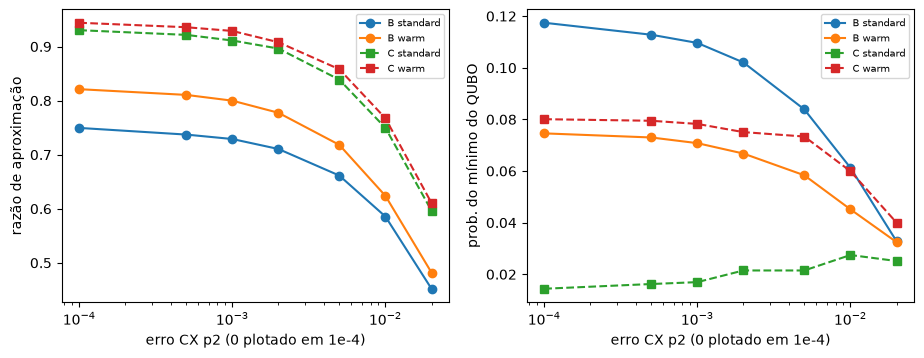

In [9]:
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error
from qiskit import transpile

def noisy_run(c, qc, g, b, params, p2, shots=8192, seed=0):
    p = len(g); bound = qc.assign_parameters({**{g[l]: params[l] for l in range(p)}, **{b[l]: params[p + l] for l in range(p)}}); bound.measure_all()
    nm = NoiseModel()
    if p2 > 0:
        nm.add_all_qubit_quantum_error(depolarizing_error(p2, 2), ['cx']); nm.add_all_qubit_quantum_error(depolarizing_error(p2 / 10, 1), ['sx', 'x'])
    sim = AerSimulator(noise_model=nm, seed_simulator=seed)
    tq = transpile(bound, sim, basis_gates=['cx', 'rz', 'sx', 'x'], optimization_level=1, seed_transpiler=0)
    cnt = sim.run(tq, shots=shots).result().get_counts()
    n = c['prob'].n; pv = np.zeros(2 ** n)
    for k, v in cnt.items(): pv[sum(int(ch) << i for i, ch in enumerate(reversed(k.replace(' ', ''))))] += v
    return pv / pv.sum()

NOISE = [0, 5e-4, 1e-3, 2e-3, 5e-3, 1e-2, 2e-2]; rows = []
for ck in CFGS:
    c = CASE[(ck, 'principal')]
    for v in ('standard', 'warm'):
        best = min((store[('principal', ck, v, 2, sd)] for sd in SEEDS), key=lambda r: r['loss'])
        for p2 in NOISE:
            pv = noisy_run(c, best['circuit'], best['g'], best['b'], best['params'], p2); m = metrics(c, pv)
            rows.append(dict(cfg=ck, variant=v, p2=p2, **m))
NZ = pd.DataFrame(rows); NZ.to_csv('../results/exp09_noise.csv', index=False)
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
for ck, ls in (('B', '-o'), ('C', '--s')):
    for v in ('standard', 'warm'):
        d = NZ[(NZ.cfg == ck) & (NZ.variant == v)]; x = np.maximum(d.p2, 1e-4)
        axs[0].semilogx(x, d.AR, ls, label=f'{ck} {v}'); axs[1].semilogx(x, d.P_qubo_gs, ls, label=f'{ck} {v}')
axs[0].set_ylabel('razão de aproximação'); axs[1].set_ylabel('prob. do mínimo do QUBO')
for a in axs: a.set_xlabel('erro CX p2 (0 plotado em 1e-4)'); a.legend(fontsize=7)
fig.savefig('../results/figures/09_noise.png', dpi=150, bbox_inches='tight')
NZ.pivot_table(index=['cfg', 'variant'], columns='p2', values='AR').round(3)

## E10 — Plano escolhido avaliado em cenários fora da amostra (avaliação parcial)
50 sequências sintéticas por **bootstrap sazonal de blocos de 3 meses** (semente fixa) sobre os mesmos anos. **Atenção:** os sorteios recombinam os mesmos anos usados na otimização, então **não são independentes** da amostra de treino; é uma checagem de sensibilidade, não validação estatística. Para validação por ano omitido, ver o experimento 06.

In [10]:
def bootstrap_instance(ck, n=50, seed=777, block_len=3):
    seq = SEQ[ck]; elig = pd.DataFrame({'year': seq.year, 'month': seq.month, 'eligible': True}); rng = np.random.default_rng(seed); rows = []
    for d in range(n):
        src = T.seasonal_block_draw(elig, block_len, rng)
        for b, y in zip(T.blocks(block_len), src):
            for m in b: r = seq[(seq.year == y) & (seq.month == m)].iloc[0]; rows.append(dict(year=1000 + d, month=m, days=r.days, I_hm3=r.I_hm3, e_mm=r.e_mm))
    return pd.DataFrame(rows)
rows = []
for ck in CFGS:
    c = CASE[(ck, 'principal')]; ib = make_instance(bootstrap_instance(ck), CFGS[ck], 200, 'bs', demand_scale=2)
    # melhor execução padrão p=2 (menor loss) → amostra de menor energia do QUBO
    best = min((store[('principal', ck, 'standard', 2, sd)] for sd in SEEDS), key=lambda r: r['loss']); i_q, _ = best_of_shots(c, best['probs'], 0)
    def bits_of(i): return np.array([(i >> k) & 1 for k in range(8)])
    plans = {'ótimo discreto real': bits_of(c['i_true']), 'mínimo do QUBO': bits_of(c['i_qgs']), 'QAOA (melhor amostra, p=2)': bits_of(i_q)}
    for name, bits in plans.items():
        s_in = Dd.objective(INST[ck], dz, bits, LAM, ALPHA); s_out = Dd.objective(ib, dz, bits, LAM, ALPHA); sm = summarize(ib, dz.decode(bits, ib), ALPHA)
        rows.append(dict(cfg=ck, plano=name, J_amostra=s_in, J_bootstrap=s_out, deficit_urb_bs_pct=sm['exp_deficit_urban_pct'], deficit_irr_bs_pct=sm['exp_deficit_irrig_pct']))
    for name, a in (('MILP contínuo', c and CASE[(ck, 'cont')]['a']), ('E01 linear', plan_linear(INST[ck])), ('E02 prioritário', plan_priority(INST[ck]))):
        s_in = summarize(INST[ck], a, ALPHA); s_out = summarize(ib, a, ALPHA)
        rows.append(dict(cfg=ck, plano=name, J_amostra=(1 - LAM) * s_in['exp_loss'] + LAM * s_in['cvar_loss'], J_bootstrap=(1 - LAM) * s_out['exp_loss'] + LAM * s_out['cvar_loss'],
                         deficit_urb_bs_pct=s_out['exp_deficit_urban_pct'], deficit_irr_bs_pct=s_out['exp_deficit_irrig_pct']))
OOS = pd.DataFrame(rows); OOS.to_csv('../results/exp10_out_of_sample_bootstrap.csv', index=False); OOS.round(2)

,cfg,plano,J_amostra,J_bootstrap,deficit_urb_bs_pct,deficit_irr_bs_pct
0,B,ótimo discreto real,93.88,100.52,2.03,69.81
1,B,mínimo do QUBO,99.32,100.88,7.62,62.69
2,B,"QAOA (melhor amostra, p=2)",99.32,100.88,7.62,62.69
3,B,MILP contínuo,91.89,97.95,1.27,69.09
4,B,E01 linear,138.74,139.31,47.71,49.83
5,B,E02 prioritário,101.37,102.54,6.55,65.35
6,C,ótimo discreto real,79.54,74.25,7.39,28.62
7,C,mínimo do QUBO,83.76,77.58,4.29,38.95
8,C,"QAOA (melhor amostra, p=2)",83.76,77.58,4.29,38.95
9,C,MILP contínuo,76.37,75.05,10.32,23.38


## Conclusões e limites
Preenchidas no relatório (seção 4.8) a partir das tabelas acima. Resumo metodológico: (i) o QUBO é um **substituto aproximado**; (ii) o espaço de 256 estados é pequeno demais para qualquer alegação de vantagem; (iii) ruído, p e o QUBO denso limitam o QAOA; (iv) o desempenho computacional não se traduz automaticamente em qualidade hidrológica.